<a href="https://colab.research.google.com/github/fesilveiraeng/Trabalho_IA/blob/main/GradienteDescendente.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
#Conecta ao Google Drive

from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [11]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Comprimento: 23 | perda inicial: 9.0

1) DEMONSTRAÇÃO: VALORES FORA DE [0,1]
eta=0.25: 1.0 -> +0.5000
eta=0.50: 1.0 -> +0.0000
eta=0.75: 1.0 -> -0.5000
eta=1.00: 1.0 -> -1.0000
eta=1.10: 1.0 -> -1.2000

2) GRADIENTE DESCENDENTE BÁSICO
delta_x registrado: True
Total de transformações: 60
Passo 01: [-0.  -0.  -0.  -0.  -0.5 -0.  -0.  -0.5 -0.  -0.  -0.  -0.  -0.5 -0.5
 -0.  -0.  -0.5 -0.5 -0.  -0.  -0.5 -0.5 -0.5]
Passo 02: [-0.   -0.   -0.   -0.   -0.25 -0.   -0.   -0.25 -0.   -0.   -0.   -0.
 -0.25 -0.25 -0.   -0.   -0.25 -0.25 -0.   -0.   -0.25 -0.25 -0.25]
Passo 03: [-0.    -0.    -0.    -0.    -0.125 -0.    -0.    -0.125 -0.    -0.
 -0.    -0.    -0.125 -0.125 -0.    -0.    -0.125 -0.125 -0.    -0.
 -0.125 -0.125 -0.125]
Passo 04: [-0.     -0.     -0.     -0.     -0.0625 -0.     -0.     -0.0625 -0.
 -0.     -0.     -0.     -0.0625 -0.0625 -0.     -0.     -0.0625 -0.0625
 -0.     -0.     -0.0625 -0.0625 -0.0625]
Passo 05: [-0.      -0.      -0.      -0.      -0.03125 -0.      -0.    

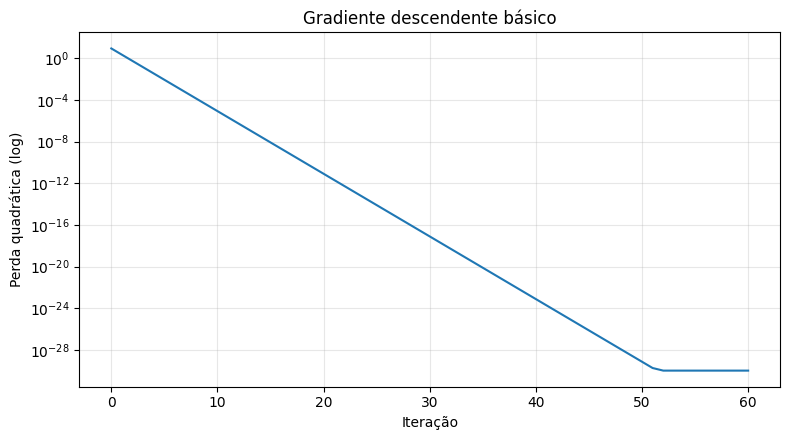


3) VERIFICAÇÃO DA REGRA DA CADEIA
Maior diferença analítico x numérico: 5.662e-10

4) EXPERIMENTOS COM DIFERENTES LAMBDAS

ANÁLISE DOS BLOCOS ATIVOS
lambda=0 | passo=3 | perda=0.140625 | C=0.558018 | blocos ativos=5
lambda=0.01 | passo=3 | perda=0.111366 | C=0.393834 | blocos ativos=5
lambda=0.05 | passo=3 | perda=0.051906 | C=0.104744 | blocos ativos=3
lambda=0.2 | passo=3 | perda=0.025238 | C=0.100919 | blocos ativos=1
lambda=1 | passo=3 | perda=0.435068 | C=0.461510 | blocos ativos=1
lambda=5 | passo=3 | perda=1.053251 | C=1.435001 | blocos ativos=1
 lambda  passos  convergiu  tempo_s     objetivo        perda  contiguidade  erro_maximo
   0.00      33       True 0.004404 1.219727e-19 1.219727e-19  6.612156e-33 1.164153e-10
   0.01      32       True 0.005049 2.486343e-19 2.486343e-19  1.615628e-32 2.309838e-10
   0.05      32       True 0.004969 7.245062e-20 7.245062e-20  1.517046e-33 1.817361e-10
   0.20      31       True 0.004905 1.311288e-19 1.311288e-19  8.769000e-33 2.732342

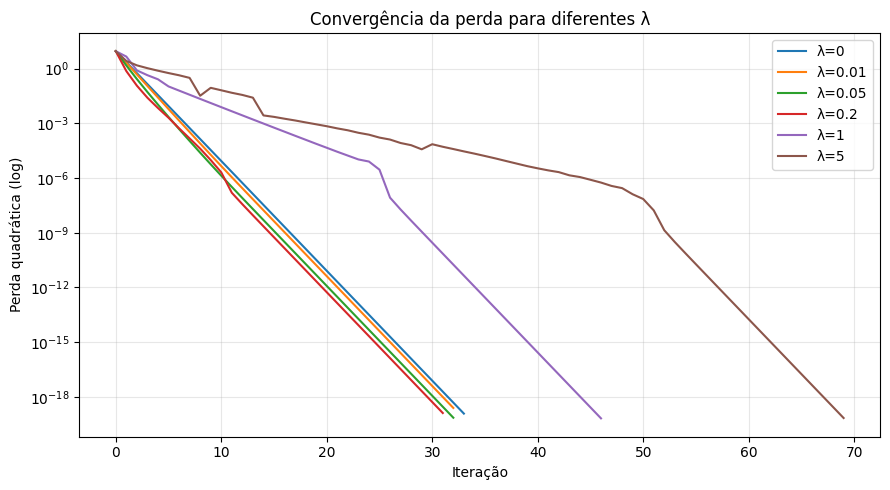

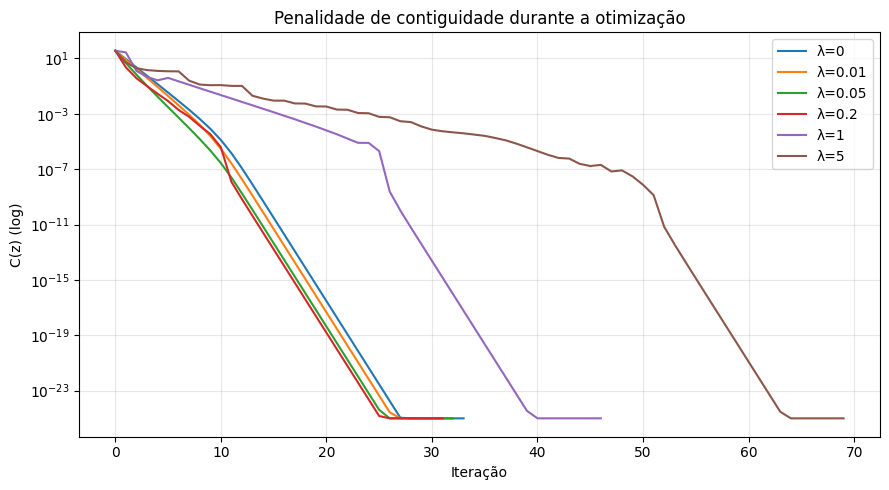

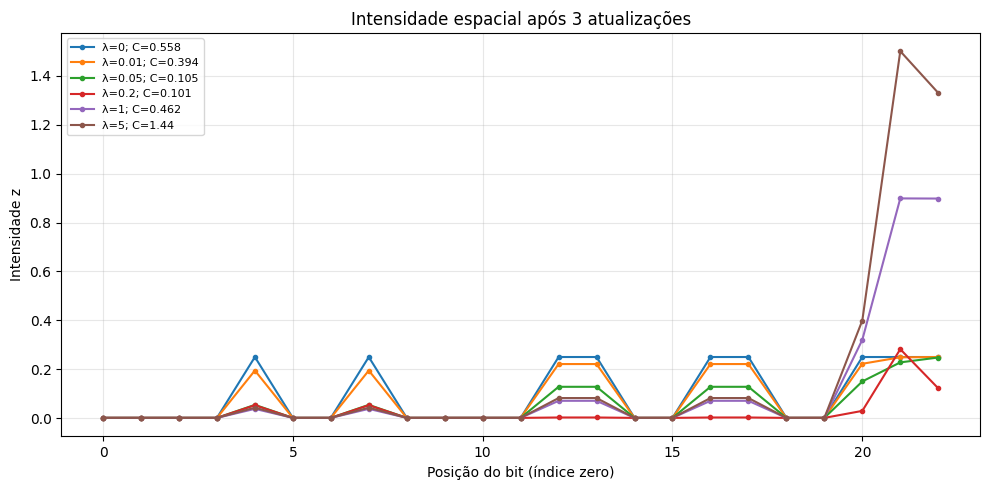


5) CONTIGUIDADE EM LIMIARES DE PERDA COMPARÁVEIS
 lambda  limiar_perda  passo  perda_observada  C_observado
   0.00           4.0      1         2.250000     8.982018
   0.00           1.0      2         0.562500     2.241018
   0.00           0.1      4         0.035156     0.138393
   0.01           4.0      1         2.075285     7.978742
   0.01           1.0      2         0.480013     1.772582
   0.01           0.1      4         0.025916     0.087269
   0.05           4.0      1         1.480320     4.668936
   0.05           1.0      2         0.267761     0.670922
   0.05           0.1      3         0.051906     0.104744
   0.20           4.0      1         0.729721     2.269541
   0.20           1.0      1         0.729721     2.269541
   0.20           0.1      3         0.025238     0.100919
   1.00           4.0      2         0.797520     1.262329
   1.00           1.0      2         0.797520     1.262329
   1.00           0.1      6         0.062220     0.219803
   5.0

In [12]:
SEQUENCIA = '00001001000011001100111'
LAMBDAS = [0.0, 0.01, 0.05, 0.2, 1.0, 5.0]
EPS = 1e-3
TOL = 1e-9
MAX_ITER = 2000


def bits_para_vetor(bits):
    if not bits or any(c not in '01' for c in bits):
        raise ValueError('Informe uma sequência binária não vazia.')
    return np.fromiter((int(c) for c in bits), dtype=float)


def perda(x, y):
    return float(np.sum((x - y) ** 2))


def gradiente_perda(x, y):
    return 2.0 * (x - y)


def intensidade(x, y, eps=EPS):
    """Intensidade suave da transformação: z_i = sqrt(g_i^2 + eps^2)."""
    g = gradiente_perda(x, y)
    return np.sqrt(g * g + eps * eps)


def penalidade_contiguidade(z):
    """Penaliza variações da intensidade entre posições adjacentes."""
    return float(np.sum(np.diff(z) ** 2))


def objetivo(x, y, lam, eps=EPS):
    return perda(x, y) + lam * penalidade_contiguidade(intensidade(x, y, eps))


def gradiente_objetivo(x, y, lam, eps=EPS):
    """Regra da cadeia para J=L+lambda*C(z(x)).

    g_i=2(x_i-y_i); z_i=sqrt(g_i^2+eps^2)
    dC/dz_i=2(2z_i-z_{i-1}-z_{i+1}) (bordas com 1 vizinho)
    dz_i/dx_i=2*g_i/z_i
    """
    g = gradiente_perda(x, y)
    if lam == 0:
        return g.copy()
    z = np.sqrt(g * g + eps * eps)
    dz = np.zeros_like(z)
    diferencas = np.diff(z)
    dz[:-1] -= 2.0 * diferencas
    dz[1:] += 2.0 * diferencas
    return g + lam * dz * (2.0 * g / z)


def diferencas_finitas(x, y, lam, h=1e-6):
    resultado = np.zeros_like(x)
    for i in range(x.size):
        xp, xm = x.copy(), x.copy()
        xp[i] += h
        xm[i] -= h
        resultado[i] = (objetivo(xp, y, lam) - objetivo(xm, y, lam)) / (2*h)
    return resultado

def descida_basica(x0, y, eta=0.25, passos=60):
    """Sem projeção: pode sair de [0,1].
    Retorna o vetor final e o histórico com cada transformação Δx.
    """
    x = x0.astype(float).copy()
    historico = [{
        'passo': 0,
        'perda': perda(x, y),
        'x': x.copy(),
        'delta_x': np.zeros_like(x)
    }]

    for k in range(1, passos + 1):
        delta_x = -eta * gradiente_perda(x, y)
        x = x + delta_x

        historico.append({
            'passo': k,
            'perda': perda(x, y),
            'x': x.copy(),
            'delta_x': delta_x.copy()
        })

    return x, historico

def descida_regularizada(x0, y, lam, eta_inicial=0.25,
                         max_iter=MAX_ITER, tol=TOL):
    """Gradiente descendente com Armijo/backtracking e sem projeção.

    Parada por norma do gradiente ou por limite de iterações.
    Registra trajetória inteira para comparar o efeito TRANSITÓRIO de lambda.
    """
    x = x0.astype(float).copy()
    t0 = time.perf_counter()
    historico = []
    convergiu = False
    for k in range(max_iter + 1):
        g = gradiente_objetivo(x, y, lam)
        norma = float(np.linalg.norm(g))
        z = intensidade(x, y)
        historico.append({
            'passo': k, 'perda': perda(x, y),
            'C': penalidade_contiguidade(z),
            'objetivo': objetivo(x, y, lam),
            'norma_gradiente': norma, 'x': x.copy(), 'z': z.copy()
        })
        if norma <= tol:
            convergiu = True
            break
        if k == max_iter:
            break
        alpha = eta_inicial
        valor = historico[-1]['objetivo']
        norma2 = norma * norma
        # Condição de Armijo: descida suficiente.
        for _ in range(70):
            candidato = x - alpha * g
            if objetivo(candidato, y, lam) <= valor - 1e-4 * alpha * norma2:
                break
            alpha *= 0.5
        else:
            break
        x = candidato
    return {
        'lambda': lam, 'x': x, 'historico': historico,
        'passos': len(historico) - 1,
        'convergiu': convergiu,
        'tempo_s': time.perf_counter() - t0
    }


def salvar_figura(nome):
    plt.tight_layout()
    plt.savefig(nome, dpi=180, bbox_inches='tight')
    plt.show()

def contar_blocos_ativos(z, limiar=0.1):
    ativos = np.asarray(z) > limiar
    return int(np.sum(ativos & ~np.r_[False, ativos[:-1]]))

def main():
    x0 = bits_para_vetor(SEQUENCIA)
    y = np.zeros_like(x0)
    print(f'Comprimento: {len(x0)} | perda inicial: {perda(x0, y):.1f}')

    print('\n1) DEMONSTRAÇÃO: VALORES FORA DE [0,1]')
    for eta in [0.25, 0.50, 0.75, 1.00, 1.10]:
        x1, _ = descida_basica(np.array([1.0]), np.array([0.0]), eta, 1)
        print(f'eta={eta:.2f}: 1.0 -> {x1[0]:+.4f}')

    print('\n2) GRADIENTE DESCENDENTE BÁSICO')
    xb, hb = descida_basica(x0, y, eta=0.25, passos=60)
    print('delta_x registrado:', 'delta_x' in hb[1])
    print('Total de transformações:', len(hb) - 1)
    for registro in hb[1:]:
        print(f"Passo {registro['passo']:02d}: {registro['delta_x']}")
    print(f'Perda inicial: {hb[0]["perda"]:.6g} | final: {hb[-1]["perda"]:.6g}')
    plt.figure(figsize=(8, 4.5))
    plt.semilogy([r['passo'] for r in hb],
                 [max(r['perda'], 1e-30) for r in hb])
    plt.xlabel('Iteração')
    plt.ylabel('Perda quadrática (log)')
    plt.title('Gradiente descendente básico')
    plt.grid(alpha=0.3)
    salvar_figura('gradiente_basico.png')

    print('\n3) VERIFICAÇÃO DA REGRA DA CADEIA')
    x_teste = np.linspace(0.05, 0.95, len(x0))
    y_teste = np.zeros_like(x_teste)
    ga = gradiente_objetivo(x_teste, y_teste, lam=0.2)
    gn = diferencas_finitas(x_teste, y_teste, lam=0.2)
    erro = float(np.max(np.abs(ga - gn)))
    print(f'Maior diferença analítico x numérico: {erro:.3e}')
    assert erro < 1e-5, 'Falha na verificação numérica do gradiente.'

    print('\n4) EXPERIMENTOS COM DIFERENTES LAMBDAS')
    resultados = [descida_regularizada(x0, y, lam) for lam in LAMBDAS]

    # ANÁLISE DOS BLOCOS ATIVOS
    print('\nANÁLISE DOS BLOCOS ATIVOS')

    for r in resultados:
        p = r['historico'][3]

        blocos = contar_blocos_ativos(p['z'], limiar=0.1)

        print(
            f"lambda={r['lambda']:g} | "
            f"passo=3 | "
            f"perda={p['perda']:.6f} | "
            f"C={p['C']:.6f} | "
            f"blocos ativos={blocos}"
        )

    linhas = []
    trajetorias = []
    for r in resultados:
        ultimo = r['historico'][-1]
        linhas.append({
            'lambda': r['lambda'], 'passos': r['passos'],
            'convergiu': r['convergiu'], 'tempo_s': r['tempo_s'],
            'objetivo': ultimo['objetivo'], 'perda': ultimo['perda'],
            'contiguidade': ultimo['C'],
            'erro_maximo': float(np.max(np.abs(r['x'] - y)))
        })
        for p in r['historico']:
            trajetorias.append({
                'lambda': r['lambda'], 'passo': p['passo'],
                'perda': p['perda'], 'C': p['C'],
                'objetivo': p['objetivo'],
                'norma_gradiente': p['norma_gradiente']
            })
    tabela = pd.DataFrame(linhas)
    trajetoria_df = pd.DataFrame(trajetorias)
    print(tabela.to_string(index=False))
    tabela.to_csv('resultados_gradiente.csv', index=False)
    trajetoria_df.to_csv('trajetorias_gradiente.csv', index=False)

    # Comparação durante a otimização, antes de C -> 0 para todos.
    plt.figure(figsize=(9, 5))
    for r in resultados:
        h = r['historico']
        plt.semilogy([p['passo'] for p in h],
                     [max(p['perda'], 1e-25) for p in h],
                     label=f'λ={r["lambda"]:g}')
    plt.xlabel('Iteração')
    plt.ylabel('Perda quadrática (log)')
    plt.title('Convergência da perda para diferentes λ')
    plt.legend()
    plt.grid(alpha=0.3)
    salvar_figura('gradiente_convergencia.png')

    plt.figure(figsize=(9, 5))
    for r in resultados:
        h = r['historico']
        plt.semilogy([p['passo'] for p in h],
                     [max(p['C'], 1e-25) for p in h],
                     label=f'λ={r["lambda"]:g}')
    plt.xlabel('Iteração')
    plt.ylabel('C(z) (log)')
    plt.title('Penalidade de contiguidade durante a otimização')
    plt.legend()
    plt.grid(alpha=0.3)
    salvar_figura('gradiente_contiguidade_trajetoria.png')

    # Intensidade no mesmo número de atualizações (não no estado final).
    passo_comum = 3
    plt.figure(figsize=(10, 5))
    for r in resultados:
        h = r['historico']
        p = h[min(passo_comum, len(h)-1)]
        plt.plot(range(len(x0)), p['z'], marker='.',
                 label=f'λ={r["lambda"]:g}; C={p["C"]:.3g}')
    plt.xlabel('Posição do bit (índice zero)')
    plt.ylabel('Intensidade z')
    plt.title(f'Intensidade espacial após {passo_comum} atualizações')
    plt.legend(fontsize=8)
    plt.grid(alpha=0.3)
    salvar_figura('gradiente_intensidade.png')

    # Comparação mais justa: C em níveis similares de perda.
    # Escolhe a primeira iteração que alcança cada limiar.
    alvos_perda = [4.0, 1.0, 0.1]
    pareados = []
    for r in resultados:
        for limiar in alvos_perda:
            elegiveis = [p for p in r['historico'] if p['perda'] <= limiar]
            if elegiveis:
                p = elegiveis[0]
                pareados.append({
                    'lambda': r['lambda'], 'limiar_perda': limiar,
                    'passo': p['passo'], 'perda_observada': p['perda'],
                    'C_observado': p['C']
                })
    df_pareado = pd.DataFrame(pareados)
    print('\n5) CONTIGUIDADE EM LIMIARES DE PERDA COMPARÁVEIS')
    print(df_pareado.to_string(index=False))
    df_pareado.to_csv('contiguidade_por_limiar.csv', index=False)
    print('\nNota: atingir o mesmo limiar NÃO implica perdas exatamente iguais.')
    print('C(z) mede suavidade das intensidades, não garante um bloco discreto único.')
    print('\nArquivos: resultados_gradiente.csv, trajetorias_gradiente.csv,')
    print('contiguidade_por_limiar.csv e quatro figuras PNG.')


if __name__ == '__main__':
    main()

